<a href="https://colab.research.google.com/github/Ramy99999999/Flyrank-machine-learning-internship/blob/main/work/notebooks/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ramy99999999/Flyrank-machine-learning-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## Abstract

This study asks whether content items can be ranked by their risk of going dark in the following month so that a content team can prioritize which pages to review first. Using the FlyRank pseudonymized warehouse, February 2026 performance signals were used as features and March 2026 Google Search Console activity was used to define the `went_dark` outcome. A simple visibility-based baseline was compared with a logistic regression model using held-out Precision@10, Precision@20, and Precision@50. The baseline achieved 0.10, 0.20, and 0.16 respectively, while logistic regression achieved 0.10, 0.05, and 0.10. The result suggests that, for this dataset and evaluation setup, the simpler visibility-based ranking matched the tested machine-learning model at the top 10 positions and outperformed it at the top 20 and 50 positions.

## Introduction / Problem

Content teams cannot review every page with the same level of attention. A useful review system therefore needs a way to prioritize which content items deserve investigation first.

The operational question in this analysis is whether information available during February can be used to rank content according to its measured risk of going dark during March.

The challenge is that the positive outcome is relatively uncommon: only 1,159 of 29,362 modeled content items, or approximately 3.95%, were labeled `went_dark = 1`.

A simple ranking rule based on search visibility provides a useful benchmark. The question is whether a machine-learning model using several February performance signals can improve that ranking enough to justify the additional complexity.

## 1. Question

*The research question and the decision it supports.*



### Research question

Can we rank content items by their risk of going dark in the following month, so that a content team can prioritize which pages to review first?

### Decision supported

The goal is to produce a ranked review queue: content items with the highest predicted risk are reviewed first by the content team.

This is a decision-support problem. The analysis measures whether February performance signals can help prioritize items associated with a March `went_dark` outcome. It does not claim that the model explains Google's ranking algorithm or that refreshing content will causally improve performance.

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

## 2. Data

### Dataset and release

This analysis uses the FlyRank Internship — Pseudonymized Warehouse Release (v20260703).

The main source is the `fact_content_daily_performance` table, which contains daily content-level performance observations. The warehouse also contains `dim_content` and `dim_clients` tables used to provide content and client context where needed.

### Feature and outcome windows

The modeling setup uses:

- **February 2026** as the feature window.
- **March 2026** as the outcome window.

February performance signals are used to construct the features used for ranking. The March window is used only to define the subsequent `went_dark` outcome.

### Outcome definition

A content item is labeled `went_dark = 1` when it has measured Google Search Console activity during March but records zero GSC clicks across that outcome window.

### Universe and exclusions

The modeling universe requires:

- at least 100 February GSC impressions,
- at least 3 February GSC clicks,
- published content,
- content created on or before 2026-02-28.

The latest `_sample` partition is excluded from model development and evaluation so that it remains a sealed outcome/test period.

### Public-safe framing

The analysis uses pseudonymized warehouse data. Client names, private URLs, and private search queries are not included in the public research output.

In [99]:
%pip -q install duckdb huggingface_hub

In [100]:
import os
import duckdb
import pandas as pd
import numpy as np

from google.colab import userdata

In [101]:
HF_TOKEN = userdata.get("HF_TOKEN")

if not HF_TOKEN:
    raise ValueError(
        "HF_TOKEN was not found. Add your Hugging Face token to Colab Secrets."
    )

In [102]:
con = duckdb.connect()

con.execute(
    f"""
    CREATE OR REPLACE SECRET hf (
        TYPE huggingface,
        TOKEN '{HF_TOKEN}'
    )
    """
)

REL = "hf://datasets/FlyRank/internship-warehouse"

print("DuckDB connected.")
print("Warehouse:", REL)

DuckDB connected.
Warehouse: hf://datasets/FlyRank/internship-warehouse


In [103]:
daily_path = f"{REL}/fact_content_daily_performance/**/*.parquet"

check = con.execute(
    f"""
    SELECT
        COUNT(*) AS row_count,
        MIN(report_date) AS min_report_date,
        MAX(report_date) AS max_report_date
    FROM read_parquet('{daily_path}')
    """
).df()

check

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,row_count,min_report_date,max_report_date
0,78835655,2025-01-27,2026-06-30


In [104]:
schema = con.execute(
    f"""
    DESCRIBE
    SELECT *
    FROM read_parquet(
        '{REL}/fact_content_daily_performance/month=2026-03/*.parquet'
    )
    LIMIT 0
    """
).df()

schema

,column_name,column_type,null,key,default,extra
0,report_date,DATE,YES,None,None,None
1,client_hash_id,VARCHAR,YES,None,None,None
2,content_hash_id,VARCHAR,YES,None,None,None
3,client_has_gsc,BOOLEAN,YES,None,None,None
4,client_has_ga4,BOOLEAN,YES,None,None,None
5,gsc_data_available,BOOLEAN,YES,None,None,None
6,ga4_data_available,BOOLEAN,YES,None,None,None
7,gsc_impressions,BIGINT,YES,None,None,None
8,gsc_clicks,BIGINT,YES,None,None,None
9,gsc_sum_position,BIGINT,YES,None,None,None


In [105]:
grain_check = con.execute(
    f"""
    SELECT
        report_date,
        client_hash_id,
        content_hash_id,
        COUNT(*) AS n
    FROM read_parquet(
        '{REL}/fact_content_daily_performance/month=2026-03/*.parquet'
    )
    GROUP BY
        report_date,
        client_hash_id,
        content_hash_id
    HAVING COUNT(*) > 1
    LIMIT 5
    """
).df()

grain_check

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,report_date,client_hash_id,content_hash_id,n


In [106]:
feb_path = f"{REL}/fact_content_daily_performance/month=2026-02/*.parquet"
mar_path = f"{REL}/fact_content_daily_performance/month=2026-03/*.parquet"

modeling_df = con.execute(
    f"""
    WITH feb AS (
        SELECT
            client_hash_id,
            content_hash_id,

            SUM(
                CASE
                    WHEN gsc_data_available THEN gsc_impressions
                    ELSE 0
                END
            ) AS gsc_impressions_feb,

            SUM(
                CASE
                    WHEN gsc_data_available THEN gsc_clicks
                    ELSE 0
                END
            ) AS gsc_clicks_feb,

            CASE
                WHEN SUM(
                    CASE
                        WHEN gsc_data_available THEN gsc_impressions
                        ELSE 0
                    END
                ) > 0
                THEN
                    SUM(
                        CASE
                            WHEN gsc_data_available THEN gsc_sum_position
                            ELSE 0
                        END
                    )
                    /
                    SUM(
                        CASE
                            WHEN gsc_data_available THEN gsc_impressions
                            ELSE 0
                        END
                    )
                ELSE NULL
            END AS avg_position_feb,

            CASE
                WHEN COUNT(*) FILTER (
                    WHERE ga4_data_available
                ) > 0
                THEN SUM(
                    CASE
                        WHEN ga4_data_available THEN sessions_organic
                        ELSE 0
                    END
                )
                ELSE NULL
            END AS sessions_organic_feb,

            CASE
                WHEN COUNT(*) FILTER (
                    WHERE ga4_data_available
                ) > 0
                THEN SUM(
                    CASE
                        WHEN ga4_data_available THEN scroll_events
                        ELSE 0
                    END
                )
                ELSE NULL
            END AS scroll_events_feb,

            COUNT(*) FILTER (
                WHERE ga4_data_available
            ) AS ga4_available_days_feb

        FROM read_parquet('{feb_path}')
        GROUP BY
            client_hash_id,
            content_hash_id
    ),

    mar AS (
        SELECT
            client_hash_id,
            content_hash_id,

            COUNT(*) FILTER (
                WHERE gsc_data_available
            ) AS gsc_measured_days_mar,

            SUM(
                CASE
                    WHEN gsc_data_available THEN gsc_clicks
                    ELSE 0
                END
            ) AS gsc_clicks_mar

        FROM read_parquet('{mar_path}')
        GROUP BY
            client_hash_id,
            content_hash_id
    ),

    content AS (
        SELECT
            client_hash_id,
            content_hash_id,
            content_created_date,
            is_published,
            is_deleted

        FROM read_parquet(
            '{REL}/dim_content.parquet'
        )
    )

    SELECT
        feb.client_hash_id,
        feb.content_hash_id,

        feb.gsc_impressions_feb,
        feb.gsc_clicks_feb,
        feb.avg_position_feb,
        feb.sessions_organic_feb,
        feb.scroll_events_feb,
        feb.ga4_available_days_feb,

        mar.gsc_measured_days_mar,
        mar.gsc_clicks_mar,

        CASE
            WHEN mar.gsc_measured_days_mar > 0
                 AND mar.gsc_clicks_mar = 0
            THEN 1
            ELSE 0
        END AS went_dark,

        content.content_created_date,
        content.is_published,
        content.is_deleted

    FROM feb

    INNER JOIN mar
        ON feb.client_hash_id = mar.client_hash_id
        AND feb.content_hash_id = mar.content_hash_id

    INNER JOIN content
        ON feb.client_hash_id = content.client_hash_id
        AND feb.content_hash_id = content.content_hash_id

    WHERE
        feb.gsc_impressions_feb >= 100
        AND feb.gsc_clicks_feb >= 3
        AND content.is_published = TRUE
        AND content.is_deleted = FALSE
        AND content.content_created_date <= DATE '2026-02-28'
    """
).df()

print("Modeling dataset shape:", modeling_df.shape)

modeling_df.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Modeling dataset shape: (29362, 14)


,client_hash_id,content_hash_id,gsc_impressions_feb,gsc_clicks_feb,avg_position_feb,sessions_organic_feb,scroll_events_feb,ga4_available_days_feb,gsc_measured_days_mar,gsc_clicks_mar,went_dark,content_created_date,is_published,is_deleted
0,client_73cda7b4e4f265ea,content_7a105f548d9c6916,4270.0,7.0,5.960187,NaN,NaN,0,31,7.0,0,2025-02-28,True,False
1,client_73cda7b4e4f265ea,content_36c36abc7650d7af,5271.0,4.0,7.125783,NaN,NaN,0,31,6.0,0,2025-02-28,True,False
2,client_73cda7b4e4f265ea,content_a7da352b73b02668,6690.0,19.0,7.226756,NaN,NaN,0,31,13.0,0,2025-02-28,True,False
3,client_73cda7b4e4f265ea,content_aafb2ab7e5fc80d0,4314.0,14.0,6.424200,NaN,NaN,0,31,20.0,0,2025-02-28,True,False
4,client_73cda7b4e4f265ea,content_20403327d8d9374c,2756.0,8.0,6.726415,NaN,NaN,0,31,10.0,0,2025-02-28,True,False


In [107]:
print("Shape:", modeling_df.shape)

print("\nWent-dark distribution:")
print(modeling_df["went_dark"].value_counts().sort_index())

print("\nWent-dark rate:")
print(modeling_df["went_dark"].mean())

print("\nMissing values:")
print(
    modeling_df[
        [
            "gsc_impressions_feb",
            "gsc_clicks_feb",
            "avg_position_feb",
            "sessions_organic_feb",
            "scroll_events_feb",
        ]
    ].isna().sum()
)

print("\nDuplicate client-content pairs:")
print(
    modeling_df.duplicated(
        subset=["client_hash_id", "content_hash_id"]
    ).sum()
)

Shape: (29362, 14)

Went-dark distribution:
went_dark
0    28203
1     1159
Name: count, dtype: int64

Went-dark rate:
0.03947278795722362

Missing values:
gsc_impressions_feb         0
gsc_clicks_feb              0
avg_position_feb            0
sessions_organic_feb    20335
scroll_events_feb       20335
dtype: int64

Duplicate client-content pairs:
0


In [108]:
print("Impressions < 100:")
print((modeling_df["gsc_impressions_feb"] < 100).sum())

print("\nClicks < 3:")
print((modeling_df["gsc_clicks_feb"] < 3).sum())

print("\nNegative impressions:")
print((modeling_df["gsc_impressions_feb"] < 0).sum())

print("\nNegative clicks:")
print((modeling_df["gsc_clicks_feb"] < 0).sum())

print("\nInvalid average positions:")
print(
    (
        (modeling_df["avg_position_feb"] <= 0)
        | (modeling_df["avg_position_feb"].isna())
    ).sum()
)

Impressions < 100:
0

Clicks < 3:
0

Negative impressions:
0

Negative clicks:
0

Invalid average positions:
0


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*



### Features

The ranking model uses February 2026 performance signals:

- `gsc_impressions_feb`
- `gsc_clicks_feb`
- `avg_position_feb`
- `sessions_organic_feb`
- `scroll_events_feb`

The GA4-derived features can be unavailable for some content items, so explicit missingness indicators were added for `sessions_organic_feb` and `scroll_events_feb`. Missing numeric values were then median-imputed inside the modeling pipeline.

Client and content IDs were used only to identify and group observations. They were not used as predictive features.

### Baseline

The baseline ranks content by:

`1 / log1p(gsc_impressions_feb)`

This gives higher priority to content with lower February search visibility. It is intentionally simple and provides a decision-focused benchmark for evaluating whether the machine-learning model adds useful ranking signal.

### Model

The tested machine-learning model is a logistic regression classifier with:

- median imputation for missing numeric values,
- standardization of features,
- balanced class weights,
- `random_state=42`.

The model produces a predicted probability of `went_dark = 1`, which is used as the ranking score.

### Validation design

The dataset was split into 80% training and 20% held-out test data using a stratified split with `random_state=42`.

This produced:

- 23,489 training observations
- 5,873 held-out test observations

The positive rate remained approximately 3.95% in both sets.

The baseline was evaluated on the exact same held-out test rows as the logistic regression model so that the comparison was fair.

### Evaluation metric

The primary metric is Precision@K, measured at K = 10, 20, and 50.

Precision@K answers a practical question: among the first K items placed in the review queue, what fraction actually went dark in the March outcome window?

### Leakage and framing checks

The February feature window is separated from the March outcome window. The outcome is therefore not used as a February feature.

The latest `_sample` partition is kept sealed and is not used for model development or evaluation.

The analysis is designed as decision support: the model ranks items associated with a measured future outcome, but the results do not establish causation or explain Google's ranking algorithm.

In [109]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Make the row order deterministic before the train/test split.
# This ensures random_state=42 produces the same split across runs.
modeling_df = modeling_df.sort_values(
    ["client_hash_id", "content_hash_id"]
).reset_index(drop=True)

feature_columns = [
    "gsc_impressions_feb",
    "gsc_clicks_feb",
    "avg_position_feb",
    "sessions_organic_feb",
    "scroll_events_feb",
]

X = modeling_df[feature_columns].copy()
y = modeling_df["went_dark"].copy()

# Explicit missingness indicators
X["sessions_organic_missing"] = (
    X["sessions_organic_feb"].isna().astype(int)
)

X["scroll_events_missing"] = (
    X["scroll_events_feb"].isna().astype(int)
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training positive rate:", y_train.mean())
print("Test positive rate:", y_test.mean())

Training rows: 23489
Test rows: 5873
Training positive rate: 0.03946528162118439
Test positive rate: 0.03950280946705261


In [110]:
model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42,
            class_weight="balanced"
        )
    )
])

model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


In [111]:
test_probabilities = model.predict_proba(X_test)[:, 1]

print("Predictions generated:", len(test_probabilities))
print("Minimum predicted risk:", test_probabilities.min())
print("Maximum predicted risk:", test_probabilities.max())

Predictions generated: 5873
Minimum predicted risk: 0.0
Maximum predicted risk: 0.9962140693638818


In [112]:
def precision_at_k_predictions(y_true, scores, k):
    order = np.argsort(scores)[::-1]
    top_k_indices = order[:k]
    return y_true.iloc[top_k_indices].mean()


model_results = {
    "P@10": precision_at_k_predictions(
        y_test,
        test_probabilities,
        10
    ),
    "P@20": precision_at_k_predictions(
        y_test,
        test_probabilities,
        20
    ),
    "P@50": precision_at_k_predictions(
        y_test,
        test_probabilities,
        50
    ),
}

print("Logistic Regression — Test Precision@K")

for k, value in model_results.items():
    print(f"{k}: {value:.3f}")

Logistic Regression — Test Precision@K
P@10: 0.100
P@20: 0.050
P@50: 0.100


In [113]:
modeling_df["baseline_score"] = (
    1 / np.log1p(modeling_df["gsc_impressions_feb"])
)

print("Baseline score created.")

Baseline score created.


In [114]:
test_baseline_scores = modeling_df.loc[
    X_test.index,
    "baseline_score"
]

baseline_test_results = {
    "P@10": precision_at_k_predictions(
        y_test,
        test_baseline_scores,
        10
    ),
    "P@20": precision_at_k_predictions(
        y_test,
        test_baseline_scores,
        20
    ),
    "P@50": precision_at_k_predictions(
        y_test,
        test_baseline_scores,
        50
    ),
}

print("Baseline — Held-out Test Precision@K")

for k, value in baseline_test_results.items():
    print(f"{k}: {value:.3f}")

Baseline — Held-out Test Precision@K
P@10: 0.100
P@20: 0.200
P@50: 0.160


In [115]:
comparison = pd.DataFrame({
    "Metric": ["Precision@10", "Precision@20", "Precision@50"],
    "Baseline": [
        baseline_test_results["P@10"],
        baseline_test_results["P@20"],
        baseline_test_results["P@50"],
    ],
    "Logistic Regression": [
        model_results["P@10"],
        model_results["P@20"],
        model_results["P@50"],
    ],
})

comparison

,Metric,Baseline,Logistic Regression
0,Precision@10,0.10,0.10
1,Precision@20,0.20,0.05
2,Precision@50,0.16,0.10


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*



The held-out test set contains 5,873 observations and has a `went_dark` rate of approximately 3.95%.

The simple visibility-based baseline matched the logistic regression model at Precision@10 and outperformed it at Precision@20 and Precision@50:

| Metric | Baseline | Logistic Regression |
|---|---:|---:|
| Precision@10 | 0.10 | 0.10 |
| Precision@20 | 0.20 | 0.05 |
| Precision@50 | 0.16 | 0.10 |

At the top 10 positions, both approaches identified 1 `went_dark` item. At the top 20 positions, the baseline identified 4 `went_dark` items compared with 1 for logistic regression. At the top 50 positions, the baseline identified 8 compared with 5 for logistic regression.

The result does not support replacing the simple visibility baseline with the tested logistic regression model. For this dataset, feature set, model, and validation design, the simpler ranking rule performed at least as well at the smallest review queue and better at the larger evaluated queues.

This is an observed evaluation result rather than evidence that the baseline is universally better. Different features, models, time periods, or validation designs could produce different results.

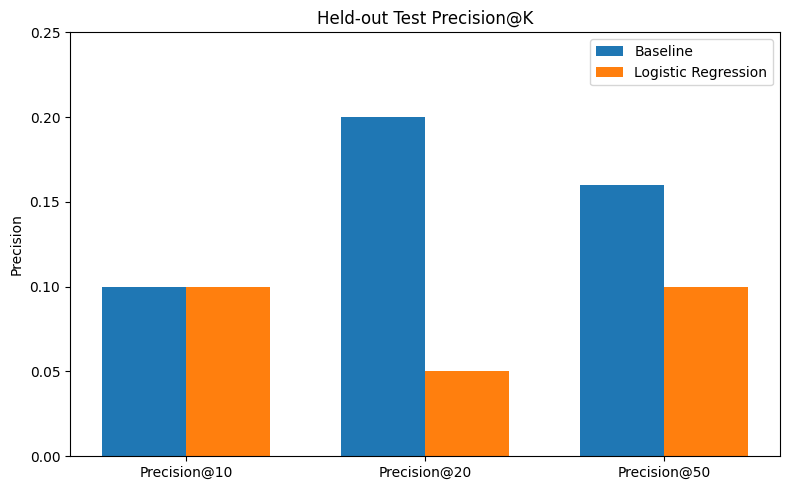

In [116]:
import matplotlib.pyplot as plt

metrics = ["Precision@10", "Precision@20", "Precision@50"]
baseline_values = [
    baseline_test_results["P@10"],
    baseline_test_results["P@20"],
    baseline_test_results["P@50"],
]
model_values = [
    model_results["P@10"],
    model_results["P@20"],
    model_results["P@50"],
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, baseline_values, width, label="Baseline")
plt.bar(x + width/2, model_values, width, label="Logistic Regression")

plt.xticks(x, metrics)
plt.ylabel("Precision")
plt.title("Held-out Test Precision@K")
plt.ylim(0, 0.25)
plt.legend()
plt.tight_layout()
plt.show()

## 5. Limitations

*What this work cannot claim.*



This analysis has several important limitations.

First, the `went_dark` outcome is defined from measured Google Search Console activity. A `went_dark = 1` label means that the content had measured GSC activity during March but recorded zero GSC clicks across that outcome window. It does not establish why the clicks became zero.

Second, GA4-derived data is unavailable for many observations. Missing `sessions_organic_feb` and `scroll_events_feb` values were therefore retained as missingness indicators and median-imputed inside the modeling pipeline. This analysis does not establish why those measurements are unavailable.

Third, the tested feature set is limited to the available February performance signals. Additional historical, content, technical, query-level, or other features could change the ranking performance.

Fourth, the evaluation covers one feature month and one subsequent outcome month. The results should therefore be treated as a directional evaluation of this specific setup rather than evidence that the same performance will hold across future months.

Finally, this is a decision-support analysis. It does not explain Google's ranking algorithm, prove that a page caused its own traffic decline, or demonstrate that refreshing content will causally increase traffic.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*



### 1. Use the visibility baseline as the current review queue

The held-out evaluation shows that the simple visibility-based baseline matched the tested logistic regression model at Precision@10 and outperformed it at Precision@20 and Precision@50.

For the current feature set and evaluation period, the operational recommendation is therefore to prioritize content using the baseline rather than replacing it with the tested machine-learning model.

### 2. Review the highest-ranked content first

The ranking should be used as a triage mechanism. Content at the top of the queue should receive human review first, allowing the team to investigate recent performance, content condition, and possible reasons for declining search activity.

### 3. Do not treat the ranking as an automatic diagnosis

A high-risk ranking means that an item deserves attention. It does not prove that the content is failing, identify the cause of the outcome, or guarantee that a refresh will improve performance.

### 4. Keep the baseline as the benchmark for future experiments

Any future model should be compared against this simple baseline using the same type of held-out evaluation. A more complicated model should only replace the baseline if it demonstrates a meaningful improvement in the ranking metrics.

### 5. Expand the feature set before attempting more complex models

Future experiments could incorporate additional historical performance, content characteristics, technical signals, or other public-safe features. These should be evaluated with the same time-separated decision framework.

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

## 7. Artifacts the paper embeds

The research paper uses three main evidence artifacts.

1. **Held-out Precision@K comparison:** a chart comparing the visibility baseline with logistic regression at K = 10, 20, and 50.

2. **Went-dark outcome distribution:** a chart showing the number of content items that did and did not receive the `went_dark` label.

3. **Evaluation table:** the exact held-out Precision@K values used to support the main conclusion.

The artifacts are intentionally limited to the evidence needed to understand the decision. Together they show the outcome imbalance, the ranking performance, and the comparison between the simple baseline and the tested machine-learning model.

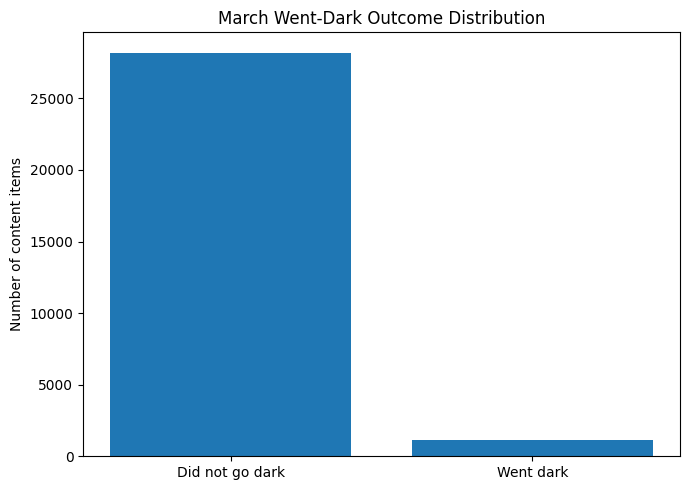

In [117]:
outcome_counts = modeling_df["went_dark"].value_counts().sort_index()

labels = ["Did not go dark", "Went dark"]
values = [
    outcome_counts.get(0, 0),
    outcome_counts.get(1, 0),
]

plt.figure(figsize=(7, 5))
plt.bar(labels, values)

plt.ylabel("Number of content items")
plt.title("March Went-Dark Outcome Distribution")
plt.tight_layout()
plt.show()

In [118]:
comparison

,Metric,Baseline,Logistic Regression
0,Precision@10,0.10,0.10
1,Precision@20,0.20,0.05
2,Precision@50,0.16,0.10


## 8. Reproducibility

The analysis was developed in Google Colab using Python, DuckDB, pandas, NumPy, and scikit-learn.

The warehouse was queried directly through DuckDB from the FlyRank pseudonymized warehouse release. February 2026 was used as the feature window and March 2026 as the outcome window.

The modeling dataset was sorted deterministically by `client_hash_id` and `content_hash_id` before the train/test split. The evaluation uses an 80/20 stratified split with `random_state=42`.

The final held-out comparison is:

| Metric | Baseline | Logistic Regression |
|---|---:|---:|
| Precision@10 | 0.10 | 0.10 |
| Precision@20 | 0.20 | 0.05 |
| Precision@50 | 0.16 | 0.10 |

The notebook contains the data construction, validation checks, baseline, model, evaluation, and visualization steps used to produce these results.

## 9. Acknowledgments & data credit

This work was completed as part of the FlyRank AI Internship.

The analysis uses the FlyRank Internship — Pseudonymized Warehouse Release (v20260703). The dataset is used for research and learning within the scope of the internship, and the public-facing analysis intentionally excludes client names, private URLs, and private search queries.

Data and project credit: FlyRank — https://flyrank.ai

## ML-12 — 5-minute demo outline

1. **Problem:** Explain that the goal is to prioritize content items for review based on their risk of going dark in the following month.

2. **Data:** Show the February feature window, March outcome window, filtering rules, and the 29,362-item modeling dataset.

3. **Method:** Explain the simple visibility baseline and the logistic regression model, including the held-out 80/20 evaluation.

4. **Result:** Show the Precision@K comparison and explain that the baseline matched logistic regression at Precision@10 and outperformed it at Precision@20 and Precision@50.

5. **Recommendation:** Explain that the baseline should remain the current review queue and that future ML experiments should be required to outperform it on a comparable held-out evaluation.

I completed my FlyRank AI Internship capstone on ranking content by its risk of going dark in the following month.

I compared a simple search-visibility baseline against logistic regression using a held-out evaluation and Precision@K.

The interesting result: the simpler baseline matched the ML model at the top 10 positions and outperformed it at the top 20 and 50 positions. A useful ML project isn't always about proving that ML wins — sometimes the strongest result is discovering that a simpler approach is better.

#MachineLearning #AI #DataScience #Internship

## Employer-facing summary

I built a decision-support pipeline to rank content items by their measured risk of going dark in the following month. I worked with a large pseudonymized warehouse using DuckDB and Python, defined a leakage-aware time-separated evaluation, and compared a logistic regression model against a simple operational baseline. The final evaluation showed that the simpler baseline matched the tested ML model at Precision@10 and outperformed it at Precision@20 and Precision@50.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
